# STAGE 2 — TASK 2: K-Means | HomeOffice

## 1. Đọc dữ liệu gốc và hai bộ đặc trưng do Task 1 xuất

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

df = pd.read_json("clean_data.json")
scaled_df = pd.read_csv("Task5_Streamlit/artifacts/homeoffice_features_scaled.csv")
pca_df = pd.read_csv("Task5_Streamlit/artifacts/homeoffice_pca_transformed.csv")
features = ["price_vnd", "rating_num", "length_cm", "width_cm", "height_cm"]
pc_columns = [c for c in pca_df.columns if c.startswith("PC")]

# Kiểm tra liên kết theo mã sản phẩm để tránh ghép nhầm hàng
for name, data in [("Scaled", scaled_df), ("PCA", pca_df)]:
    if len(data) != len(df) or not df["product_id"].astype(str).reset_index(drop=True).equals(data["product_id"].astype(str)):
        raise ValueError(f"{name}: số hàng hoặc thứ tự product_id khác dữ liệu sạch; hãy chạy lại Task 1.")

X_scaled = scaled_df[features].to_numpy(dtype=float)
X_pca = pca_df[pc_columns].to_numpy(dtype=float)
n_components = len(pc_columns)
variance_path = "Task5_Streamlit/artifacts/homeoffice_pca_variance_report.csv"
variance_report = pd.read_csv(variance_path)
kept = float(variance_report["Explained Variance Ratio"].iloc[:n_components].sum())
print(f"Đã đọc {len(df)} sản phẩm, {len(features)} biến chuẩn hóa, {n_components} thành phần PCA.")
print(f"Phương sai giữ lại: {kept:.2%}")
display(pca_df.head())


Đã đọc 336 sản phẩm, 5 biến chuẩn hóa, 4 thành phần PCA.
Phương sai giữ lại: 91.72%


,product_id,PC1,PC2,PC3,PC4
0,HBON015,0.016142,-0.054224,0.776483,0.318684
1,HBTC055,3.925029,-0.212448,-1.693192,-0.897805
2,HBXC069,1.150264,0.372477,0.728057,-0.437236
3,HBRT141,0.744852,0.556820,0.038469,-0.643152
4,HBCO083,-0.600076,-0.175606,1.553166,0.102730


## 2. Đánh giá K = 2 đến 10 trên dữ liệu chuẩn hóa và PCA (đọc từ Task 1)

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
k_values = list(range(2, min(11, len(df))))
rows = []
for space_name, values in [("Original scaled", X_scaled), ("PCA reduced", X_pca)]:
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = model.fit_predict(values)
        sizes = np.bincount(labels, minlength=k)
        rows.append({"Không gian": space_name, "K": k,
                     "WCSS": model.inertia_,
                     "Silhouette": silhouette_score(values, labels),
                     "Cụm nhỏ nhất": int(sizes.min()),
                     "Cụm lớn nhất": int(sizes.max())})
results = pd.DataFrame(rows)
display(results.round(4))

c:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\ASUS\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ASUS\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

,Không gian,K,WCSS,Silhouette,Cụm nhỏ nhất,Cụm lớn nhất
0,Original scaled,2,1350.6116,0.2280,117,219
1,Original scaled,3,1064.6696,0.2728,17,219
2,Original scaled,4,883.7835,0.2463,17,134
3,Original scaled,5,796.2013,0.2597,16,133
4,Original scaled,6,698.5348,0.2595,14,126
5,Original scaled,7,634.1519,0.2634,1,127
6,Original scaled,8,579.1249,0.2497,2,118
7,Original scaled,9,525.3597,0.2283,2,80
8,Original scaled,10,495.8239,0.2452,2,82
9,PCA reduced,2,1211.4394,0.2421,117,219


## 3. Elbow Method và Silhouette Analysis

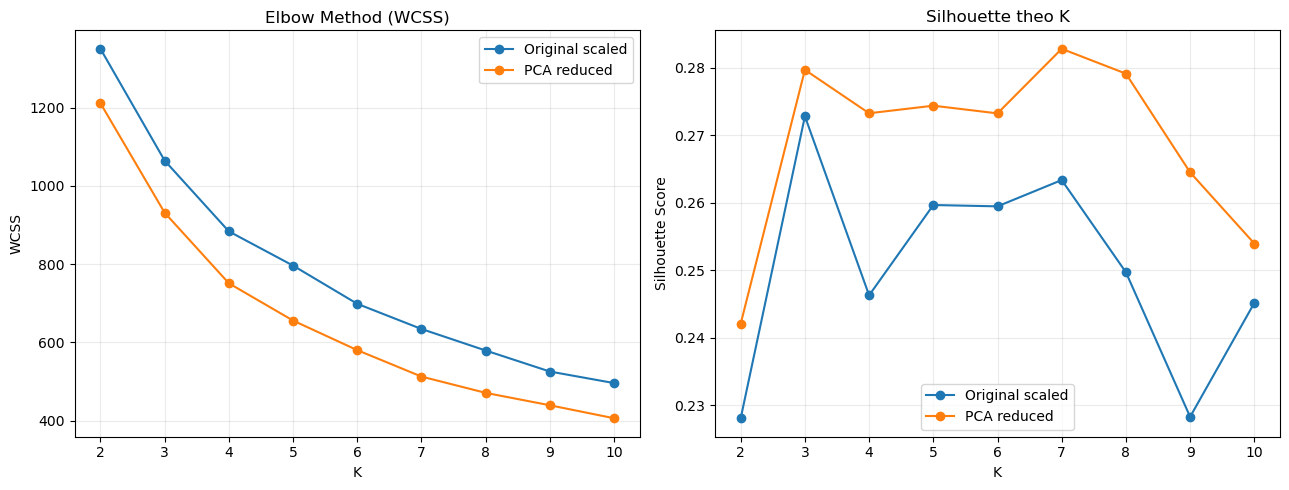

Lưu ý: WCSS giữa hai không gian khác số chiều không nên so trực tiếp theo độ lớn;
hãy đọc hình dạng đường Elbow trong từng không gian.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for space_name, group in results.groupby("Không gian"):
    axes[0].plot(group["K"], group["WCSS"], marker="o", label=space_name)
    axes[1].plot(group["K"], group["Silhouette"], marker="o", label=space_name)
axes[0].set(title="Elbow Method (WCSS)", xlabel="K", ylabel="WCSS")
axes[1].set(title="Silhouette theo K", xlabel="K", ylabel="Silhouette Score")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.25); ax.set_xticks(k_values)
plt.tight_layout(); plt.show()
print("Lưu ý: WCSS giữa hai không gian khác số chiều không nên so trực tiếp theo độ lớn;")
print("hãy đọc hình dạng đường Elbow trong từng không gian.")

## 4. Chọn K và huấn luyện hai mô hình
Chọn K có Silhouette cao nhất **trên không gian PCA** để làm mô hình cuối. Đánh giá thêm độ cân bằng kích thước cụm; nếu muốn ưu tiên khả năng diễn giải, có thể điều chỉnh `chosen_k` sau khi xem bảng và biểu đồ. Dùng cùng K cho hai mô hình để so sánh.

In [4]:
pca_scores = results[results["Không gian"] == "PCA reduced"]
best_k = int(pca_scores.loc[pca_scores["Silhouette"].idxmax(), "K"])
chosen_k = best_k  # Có thể thay bằng K khác sau khi xem Elbow + Silhouette
print("K được chọn:", chosen_k)
original_model = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
pca_model = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
labels_original = original_model.fit_predict(X_scaled)
labels_pca = pca_model.fit_predict(X_pca)
sil_original = silhouette_score(X_scaled, labels_original)
sil_pca = silhouette_score(X_pca, labels_pca)
ari = adjusted_rand_score(labels_original, labels_pca)
comparison = pd.DataFrame({
    "Mô hình": ["Trước PCA (5 biến)", f"Sau PCA ({n_components} PC)"],
    "K": [chosen_k, chosen_k],
    "Silhouette": [sil_original, sil_pca],
    "Số cụm": [len(np.unique(labels_original)), len(np.unique(labels_pca))]
})
display(comparison.round(4))
print(f"Adjusted Rand Index giữa hai bộ nhãn: {ari:.4f}")
print("Số phần tử từng cụm trước PCA:", dict(zip(*np.unique(labels_original, return_counts=True))))
print("Số phần tử từng cụm sau PCA:", dict(zip(*np.unique(labels_pca, return_counts=True))))

K được chọn: 7


c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,Mô hình,K,Silhouette,Số cụm
0,Trước PCA (5 biến),7,0.2634,7
1,Sau PCA (4 PC),7,0.2828,7


Adjusted Rand Index giữa hai bộ nhãn: 0.7683
Số phần tử từng cụm trước PCA: {np.int32(0): np.int64(83), np.int32(1): np.int64(16), np.int32(2): np.int64(127), np.int32(3): np.int64(1), np.int32(4): np.int64(19), np.int32(5): np.int64(36), np.int32(6): np.int64(54)}
Số phần tử từng cụm sau PCA: {np.int32(0): np.int64(114), np.int32(1): np.int64(86), np.int32(2): np.int64(30), np.int32(3): np.int64(15), np.int32(4): np.int64(55), np.int32(5): np.int64(1), np.int32(6): np.int64(35)}


## 5. Gắn Cluster_Label và mô tả từng cụm

In [5]:
df_result = df.copy()
df_result["Cluster_Label_Original"] = labels_original
df_result["Cluster_Label_PCA"] = labels_pca
df_result["Cluster_Label"] = labels_pca  # Mô hình chọn: K-Means sau PCA
summary = df_result.groupby("Cluster_Label").agg(
    So_san_pham=("product_id", "size"),
    Gia_trung_binh=("price_vnd", "mean"),
    Rating_trung_binh=("rating_num", "mean"),
    Dai_trung_binh=("length_cm", "mean"),
    Rong_trung_binh=("width_cm", "mean"),
    Cao_trung_binh=("height_cm", "mean")
)
# Tên mô tả dựa trên đặc điểm trung bình, không phải thứ hạng chất lượng
cluster_names = {
    0: 'Giá trung bình – rating thấp',
    1: 'Giá trung bình – rating cao',
    2: 'Giá cao – kích thước lớn',
    3: 'Sản phẩm cao – dạng đứng',
    4: 'Giá thấp – kích thước nhỏ',
    5: 'Đặc biệt – giá rất cao (1 sản phẩm)',
    6: 'Mặt rộng – giá trung bình',
}
df_result["Cluster_Name"] = df_result["Cluster_Label"].map(cluster_names)
summary.insert(0, "Ten_cum", summary.index.map(cluster_names))
display(summary.round(2))

,Ten_cum,So_san_pham,Gia_trung_binh,Rating_trung_binh,Dai_trung_binh,Rong_trung_binh,Cao_trung_binh
Cluster_Label,,,,,,,
0,Giá trung bình – rating thấp,114,3254666.67,2.04,159.33,68.18,75.45
1,Giá trung bình – rating cao,86,3014011.63,4.49,137.46,64.13,75.44
2,Giá cao – kích thước lớn,30,7922500.00,3.33,244.87,96.43,76.03
3,Sản phẩm cao – dạng đứng,15,5056333.33,3.27,77.67,39.67,173.73
4,Giá thấp – kích thước nhỏ,55,1650818.18,2.16,77.19,45.92,68.69
5,Đặc biệt – giá rất cao (1 sản phẩm),1,26000000.00,1.00,220.00,45.00,223.00
6,Mặt rộng – giá trung bình,35,3116085.71,2.91,167.54,129.34,74.20


## 6. Trực quan hóa các cụm trong không gian PCA

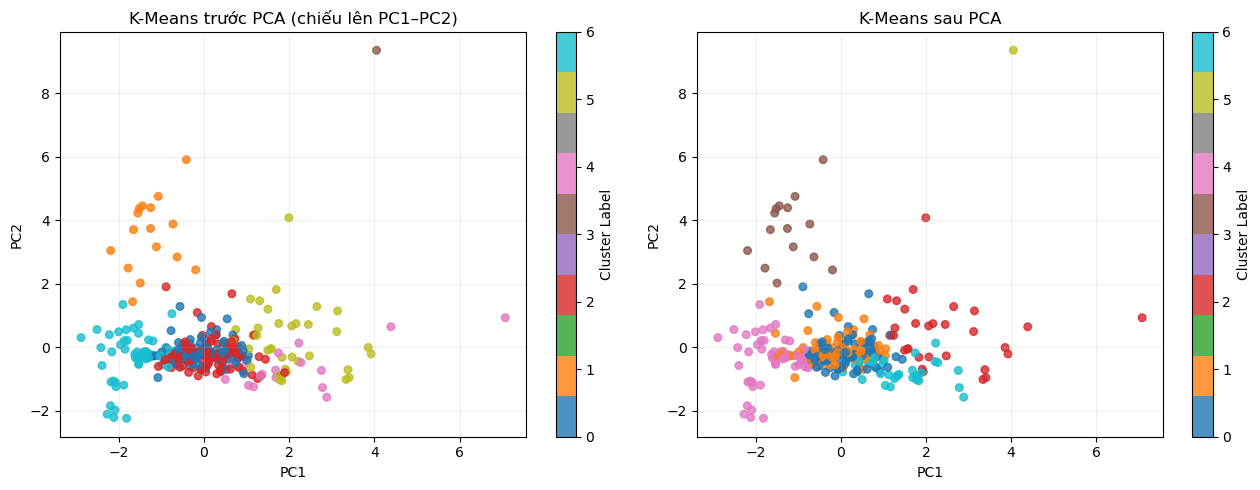

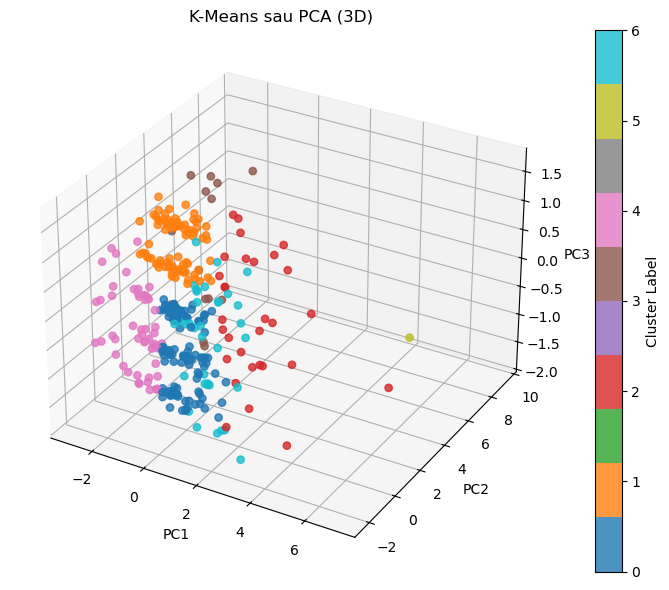

In [6]:
if X_pca.shape[1] >= 2:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, labs, title in zip(axes, [labels_original, labels_pca],
                              ["K-Means trước PCA (chiếu lên PC1–PC2)", "K-Means sau PCA"]):
        sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labs, cmap="tab10", s=30, alpha=0.8)
        ax.set(xlabel="PC1", ylabel="PC2", title=title)
        ax.grid(alpha=0.2)
        fig.colorbar(sc, ax=ax, label="Cluster Label")
    plt.tight_layout(); plt.show()
else:
    plt.figure(figsize=(8, 4))
    plt.scatter(X_pca[:, 0], np.zeros(len(df)), c=labels_pca, cmap="tab10")
    plt.xlabel("PC1"); plt.title("K-Means sau PCA")
    plt.tight_layout(); plt.show()
if X_pca.shape[1] >= 3:
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection="3d")
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
                         c=labels_pca, cmap="tab10", s=28, alpha=0.8)
    ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="K-Means sau PCA (3D)")
    fig.colorbar(scatter, ax=ax, label="Cluster Label")
    plt.tight_layout(); plt.show()

## 7. Kết luận và xuất file kết quả

In [7]:
print(f"Số sản phẩm: {len(df)} | Số biến gốc: {len(features)} | PCA: {n_components} PC ({kept:.2%}).")
print(f"Chọn K = {chosen_k} theo Silhouette cao nhất trên dữ liệu PCA.")
print("Cảnh báo: Silhouette tính ở hai không gian khác nhau; không nên diễn giải chênh lệch như một phép kiểm định tuyệt đối.")
print("Dữ liệu dùng bản (7) đã rà soát kích thước; vẫn cần xác minh một số đơn vị nguồn.")
df_result.to_csv("Task5_Streamlit/artifacts/stage2_task2_clustered.csv", index=False, encoding="utf-8-sig")
summary.to_csv("Task5_Streamlit/artifacts/stage2_task2_cluster_summary.csv", index=True, encoding="utf-8-sig")
print("Đã xuất bảng sản phẩm theo cụm và bảng thống kê cụm cho Streamlit.")
print("\nKẾT LUẬN TASK 2:")
print(f"K được chọn = {chosen_k} theo Silhouette lớn nhất trong không gian PCA.")
print(f"Silhouette gốc: {sil_original:.4f}; sau PCA: {sil_pca:.4f}; ARI: {ari:.4f}.")
print("Lưu ý: Silhouette ở hai không gian khác số chiều không phải phép so sánh tuyệt đối.")

Số sản phẩm: 336 | Số biến gốc: 5 | PCA: 4 PC (91.72%).
Chọn K = 7 theo Silhouette cao nhất trên dữ liệu PCA.
Cảnh báo: Silhouette tính ở hai không gian khác nhau; không nên diễn giải chênh lệch như một phép kiểm định tuyệt đối.
Dữ liệu dùng bản (7) đã rà soát kích thước; vẫn cần xác minh một số đơn vị nguồn.
Đã xuất bảng sản phẩm theo cụm và bảng thống kê cụm cho Streamlit.

KẾT LUẬN TASK 2:
K được chọn = 7 theo Silhouette lớn nhất trong không gian PCA.
Silhouette gốc: 0.2634; sau PCA: 0.2828; ARI: 0.7683.
Lưu ý: Silhouette ở hai không gian khác số chiều không phải phép so sánh tuyệt đối.


## Kết luận Task 2 — dựa trên dữ liệu mới

- Khảo sát **K = 2–10** với cả dữ liệu **5 biến đã chuẩn hóa** và dữ liệu sau PCA **4 thành phần**; xem đồng thời đường Elbow (WCSS) và Silhouette.
- Theo quy tắc chọn **Silhouette lớn nhất trong không gian PCA**, số cụm được chọn là **K = 7**. Đây là lựa chọn theo chỉ số, nhưng có một cụm chỉ chứa 1 sản phẩm; nên cân nhắc K = 3 như phương án phân nhóm cân bằng hơn (Silhouette PCA = 0.2797) và đối chiếu Elbow.
- Với cùng K = 7, **Silhouette trước PCA = 0.2634**, **sau PCA = 0.2828**; điểm sau PCA **cao hơn** trước PCA khi mỗi điểm được tính trong không gian tương ứng. Không diễn giải chênh lệch này như bằng chứng thống kê tuyệt đối rằng PCA cải thiện/làm giảm mô hình.
- **Adjusted Rand Index (ARI) = 0.7683** phản ánh mức độ tương đồng giữa hai cách gán cụm (1 là trùng hoàn toàn).
- Phân bố số sản phẩm theo cụm PCA: **cụm 0: 114, cụm 1: 86, cụm 2: 30, cụm 3: 15, cụm 4: 55, cụm 5: 1, cụm 6: 35**. Mã cụm là nhãn kỹ thuật, không có thứ hạng tốt/xấu.
- **Kết luận:** phân cụm K-Means đã gán `Cluster_Label` cho 336 sản phẩm. Có thể phân tích tiếp giá, rating và kích thước trung bình từng cụm trong bảng tổng hợp để diễn giải nhóm sản phẩm, không nên tự gọi đây là phân khúc khách hàng vì dữ liệu là **sản phẩm**.